# 01 — Orbit basics: J2 nodal regression

A first look through the `orbitgnc` Python module (pybind11 wrappers over `simcore`): an ISS-like
420 km circular orbit at 51.6° inclination, propagated for one day under point-mass gravity + J2
with the Dormand–Prince 5(4) integrator, sampled every minute through its dense output.

**Claim checked:** Earth's oblateness turns the orbit plane about the polar axis. To first order
in J2 the node regresses at a constant secular rate

$$\dot\Omega = -\tfrac{3}{2}\, n\, J_2 \left(\frac{R}{p}\right)^2 \cos i,\qquad n = \sqrt{\mu/a^3},\quad p = a(1-e^2),$$

about −5.0°/day here. The osculating RAAN read from each state also wobbles twice per orbit
(short-period J2 terms), so the comparison is the slope of a straight-line fit over the day.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# The module is built into build/<preset>/python (see analysis/README.md).
root = Path.cwd().resolve().parent if Path.cwd().name == "analysis" else Path.cwd().resolve()
for preset in ("release", "debug"):
    p = root / "build" / preset / "python"
    if any(p.glob("orbitgnc*")):
        sys.path.insert(0, str(p))
        break
import orbitgnc as og

mu, R, J2 = og.earth.mu, og.earth.radius, og.earth.j2

## Propagate one day with J2

In [2]:
a = R + 420e3
inc = np.radians(51.6)
t0 = og.Epoch.from_tt_seconds_since_j2000(800_000_000)
el0 = og.KeplerianElements(a_m=a, e=0.0, i_rad=inc, raan_rad=np.radians(30.0),
                           argp_rad=0.0, nu_rad=0.0)
s0 = og.state_from_elements(el0, t0)

opts = og.DpOptions()
opts.rtol, opts.atol_pos_m, opts.atol_vel_mps = 1e-12, 1e-6, 1e-9
dp = og.DormandPrince54(opts)
force = og.ForceSum().add(og.PointMassGravity()).add(og.J2Gravity())

dt = np.arange(0.0, 86400.0 + 1.0, 60.0)                # sample offsets [s]
states = og.propagate_sampled(dp, force, s0, [t0 + float(x) for x in dt])
print(f"{len(states)} samples, {dp.stats.accepted} steps, {dp.stats.force_evals} force evaluations")

1441 samples, 6760 steps, 40562 force evaluations


## RAAN against the secular rate

analytic  -4.9510 deg/day
fitted    -4.9739 deg/day
relative difference +4.62e-03
implied mean a - osculating a = -8.95 km


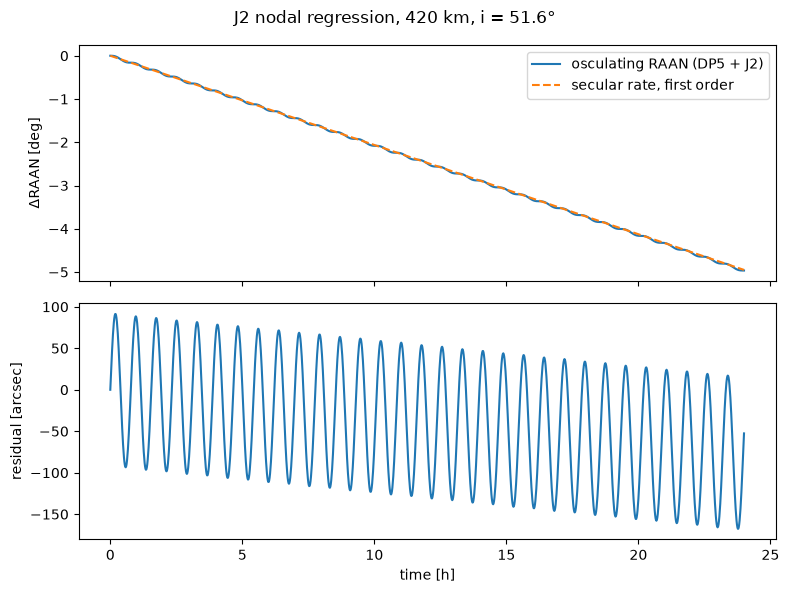

In [3]:
raan = np.unwrap([og.elements_from_state(s).raan_rad for s in states])
n = np.sqrt(mu / a**3)
rate_analytic = -1.5 * n * J2 * (R / a) ** 2 * np.cos(inc)          # e = 0: p = a
rate_fit = np.polyfit(dt, raan, 1)[0]

day = 86400.0
print(f"analytic  {np.degrees(rate_analytic) * day:+.4f} deg/day")
print(f"fitted    {np.degrees(rate_fit) * day:+.4f} deg/day")
print(f"relative difference {rate_fit / rate_analytic - 1:+.2e}")

# Mean semi-major axis that the fitted rate implies (rate ~ a^-7/2), vs the osculating start a
a_mean = a * (rate_fit / rate_analytic) ** (-2.0 / 7.0)
print(f"implied mean a - osculating a = {(a_mean - a) / 1e3:+.2f} km")

fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
hours = dt / 3600.0
ax[0].plot(hours, np.degrees(raan - raan[0]), label="osculating RAAN (DP5 + J2)")
ax[0].plot(hours, np.degrees(rate_analytic * dt), "--", label="secular rate, first order")
ax[0].set_ylabel("ΔRAAN [deg]")
ax[0].legend()
ax[1].plot(hours, np.degrees(raan - raan[0] - rate_analytic * dt) * 3600.0)
ax[1].set_ylabel("residual [arcsec]")
ax[1].set_xlabel("time [h]")
fig.suptitle("J2 nodal regression, 420 km, i = 51.6°")
fig.tight_layout()

**Reading the difference.** The formula is evaluated with the osculating *a* of the start
state, but the secular rate belongs to the *mean* orbit. A state that is circular in osculating
elements is not circular on average: J2's extra pull puts the mean orbit below the start point
(the altitude plot below swings between ~408.5 and 420 km, once per orbit). With
$\dot\Omega \propto a^{-7/2}$, the 0.46% faster regression corresponds to a mean *a* about
9 km (0.13%) lower, the same size as that swing. So the agreement is at the level first-order
theory promises, a few × J2; matching better needs a mean-element (e.g. Brouwer) initialisation.
The residual's twice-per-orbit wobble is the short-period J2 term in the osculating RAAN.

## Altitude

radius range over the day: 408.50 – 420.00 km


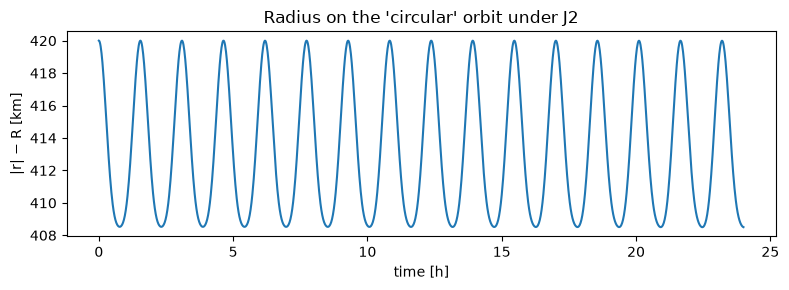

In [4]:
alt_km = (np.array([np.linalg.norm(s.r_eci) for s in states]) - R) / 1e3
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(hours, alt_km)
ax.set_xlabel("time [h]")
ax.set_ylabel("|r| − R [km]")
ax.set_title("Radius on the 'circular' orbit under J2")
fig.tight_layout()
print(f"radius range over the day: {alt_km.min():.2f} – {alt_km.max():.2f} km")